# 21 — El triage por bandas de edad: qué contexto actúa en cada parte

## Pregunta y motivo

Los cuadernos 17, 19 y 20 muestran lo mismo desde tres ángulos: el clima, las enfermedades de la ciudad y El Niño
mueven algo medible, pero los efectos que se ven en el triage total son pequeños, en el orden del 1 al 3 %, bajo un ruido semanal
del 6 %, y no son una versión reducida de los de la ciudad (cuaderno 17). El argumento de la partición es de aritmética: si una parte del triage pesa el 10 % y sube un 30 %, el total sube un 3 %.
Este cuaderno pregunta si, al repartir el triage en sus partes, cada factor externo reaparece con su tamaño
real en la parte donde actúa, y qué firma deja en cada una: con qué rezago, en qué sentido y con qué estabilidad
entre 2022-2024 y 2025-2026.

Se recorren cinco familias de factores: el clima, la salud pública de la ciudad, los regímenes (El Niño y La Niña),
los episodios locales (Feria, deslizamientos, el terremoto de 2026) y la red de aseguradoras. Cada una tiene su
reloj: el clima y la enfermedad actúan con semanas de rezago; la Feria y el terremoto, en días; la red, en meses.

## Particiones disponibles

| Partición | Cobertura | Fuente |
|---|---|---|
| **Bandas de edad** (0-4, 5-14, 15-44, 45-64, 65+) | 100 %, desde 2020 | `triage_edad.parquet` |
| **Obstétrico frente al resto** | 100 %, desde 2020 | `triage_nivel.parquet` (niveles -G) |
| Diagnósticos | 41 % (solo los ingresos) | `perfil_dx_diario` |
| Motivo de consulta (NLP) | 2025-2026, corpus sin procesar completo | `NLP/` |

Los diagnósticos no sirven como partición porque solo cubren a los pacientes que ingresan. El cruce de edad por
condición obstétrica no existe en los datos agregados disponibles, de modo que el análisis usa las dos particiones
por separado.

In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "notebooks")); warnings.filterwarnings("ignore")
import re
import numpy as np, pandas as pd, statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from matplotlib import pyplot as plt
from IPython.display import display
import indices as ix
import desenlace as de
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
BANDAS = ["0-4", "5-14", "15-44", "45-64", "65+"]
COLB = [MAGENTA, AMARILLO, AZUL, AQUA, VIOLETA]
dias = pd.date_range("2020-01-01", "2026-09-20")
ed = pd.read_parquet(RAIZ / "salidas/triage_edad.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
E = ed.pivot_table(index="dia", columns="banda", values="n", aggfunc="sum").reindex(dias).fillna(0)
nv = pd.read_parquet(RAIZ / "salidas/triage_nivel.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
obst = nv[nv.nivel.str.endswith("-G")].groupby("dia").n.sum().reindex(dias).fillna(0)
tot = nv.groupby("dia").n.sum().reindex(dias).fillna(0)
P = pd.DataFrame({"edad 0-4": E["0-4"], "edad 5-14": E["5-14"], "edad 15-44": E["15-44"], "edad 45-64": E["45-64"], "edad 65+": E["65-+"],
                  "obstétrico": obst, "no obstétrico": tot - obst, "TOTAL": tot})
P.loc["2024-03-19":"2024-03-21"] = np.nan
peso = (P.loc["2022":"2024"].mean() / P.loc["2022":"2024", "TOTAL"].mean() * 100).round(1)
print("Peso de cada parte en 2022-2024 (%):"); peso.drop("TOTAL").to_frame("% del triage")

Peso de cada parte en 2022-2024 (%):


,% del triage
edad 0-4,3.0
edad 5-14,4.4
edad 15-44,55.3
edad 45-64,18.4
edad 65+,18.8
obstétrico,11.5
no obstétrico,88.5


In [2]:
# La suma de las cinco bandas frente al total y las filas sin edad
sin_edad = ed[ed.banda.eq("sin edad")].set_index("dia").n.reindex(dias).fillna(0)
suma5 = P[["edad 0-4", "edad 5-14", "edad 15-44", "edad 45-64", "edad 65+"]].sum(axis=1)
print("Triages sin banda de edad, 2022-2026:", int(sin_edad.loc["2022":].sum()), "de", int(tot.loc["2022":].sum()))
print("Suma de las 5 bandas menos el total (2022-2026, días válidos):", int((suma5 - P.TOTAL).loc["2022":].sum()))

Triages sin banda de edad, 2022-2026: 369 de 340107
Suma de las 5 bandas menos el total (2022-2026, días válidos): -369


# 1. La estación de cada parte

Cada serie se lleva a promedio mensual de 2022 a 2025, se le resta el nivel de su año (en logaritmo) y se promedia
por mes del calendario. El resultado es la forma anual de la parte, en porcentaje frente a su propia media. La
amplitud es la distancia entre el mes más alto y el más bajo.

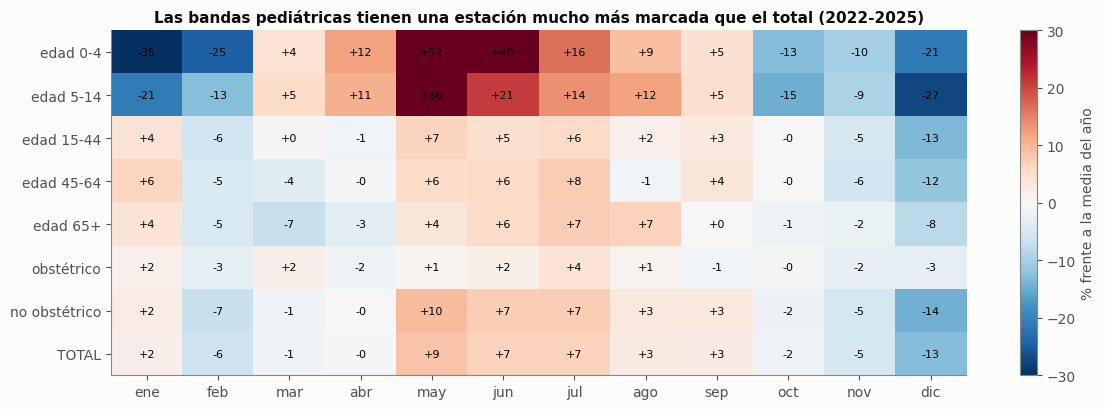

,amplitud de la estación (puntos %),mes más alto,mes más bajo
edad 0-4,86.8,may,ene
edad 5-14,63.6,may,dic
edad 15-44,20.1,may,dic
edad 45-64,19.3,jul,dic
edad 65+,15.3,jul,dic
obstétrico,7.2,jul,dic
no obstétrico,24.0,may,dic
TOTAL,21.6,may,dic


In [3]:
x = np.log(P.loc["2022":"2025"].resample("MS").mean())
forma = (np.exp((x - x.groupby(x.index.year).transform("mean")).groupby(x.index.month).mean()) - 1) * 100
fig, ax = plt.subplots(figsize=(12, 4.2))
im = ax.imshow(forma.T.values, cmap="RdBu_r", vmin=-30, vmax=30, aspect="auto")
ax.set_xticks(range(12), MESES); ax.set_yticks(range(forma.shape[1]), forma.columns); ax.grid(False)
for (i, j), v in np.ndenumerate(forma.T.values): ax.text(j, i, f"{v:+.0f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax, label="% frente a la media del año"); ax.set_title("Las bandas pediátricas tienen una estación mucho más marcada que el total (2022-2025)")
plt.tight_layout(); plt.show()
amp = (forma.max() - forma.min()).round(1).rename("amplitud de la estación (puntos %)")
pk = forma.idxmax().map(lambda m: MESES[m - 1]).rename("mes más alto"); vl = forma.idxmin().map(lambda m: MESES[m - 1]).rename("mes más bajo")
pd.concat([amp, pk, vl], axis=1)

**Lectura.** Las bandas pediátricas tienen una estación entre tres y cuatro veces más amplia que la del total, y es la única estructura estacional fuerte del hospital.

La amplitud, medida como la distancia entre el mes más alto y el más bajo, es de 86,8 puntos en 0-4 años (máximo en mayo, mínimo en enero) y de 63,6 en 5-14 (máximo en mayo, mínimo en diciembre). Los adultos y los mayores se mueven entre 15,3 y 20,1 puntos, el triage obstétrico apenas 7,2 y el total 21,6. Las dos bandas pediátricas pesan juntas el 7,4 % del triage entre 2022 y 2024 (3,0 y 4,4 %), de modo que su oscilación se diluye en el total, que sigue la forma de la banda de 15-44 años, el 55,3 % del triage.

Este es el caso del que partía el cuaderno: una estación del 87 % en una parte que pesa el 3 % se convierte en una oscilación pequeña en el total. La cautela es que el máximo de mayo coincide con la temporada de lluvias de abril y con el calendario escolar, y con siete años de datos no se pueden separar entre sí.

# 2. La composición por edad y su cambio en el tiempo

Antes de buscar el efecto de un factor conviene saber si la composición del triage por edad es estable. Si lo fuera,
las bandas serían copias a escala del total y la partición no aportaría nada.

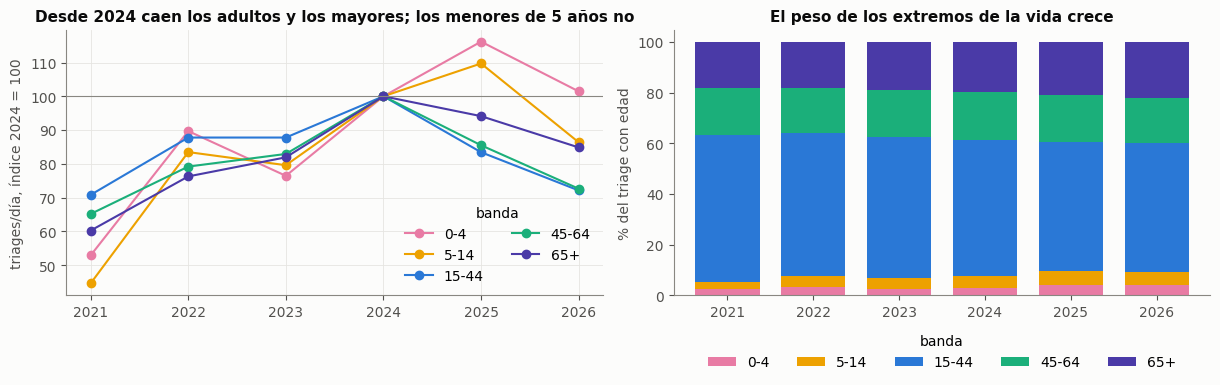

Triages/día por año y banda (2026 hasta el 20-sep):


,0-4,5-14,15-44,45-64,65+,TOTAL
2020,2.0,3.2,58.3,20.9,21.4,105.7
2021,3.6,4.6,86.5,27.9,26.7,149.3
2022,6.1,8.6,107.2,33.9,33.8,189.6
2023,5.2,8.2,107.2,35.5,36.3,192.4
2024,6.8,10.3,122.1,42.8,44.3,226.9
2025,7.9,11.3,101.9,36.6,41.7,199.6
2026,6.9,8.9,88.1,31.1,37.6,172.6


Composición (%):


,0-4,5-14,15-44,45-64,65+
2020,1.9,3.0,55.1,19.8,20.2
2021,2.4,3.0,57.9,18.7,17.9
2022,3.2,4.5,56.5,17.9,17.8
2023,2.7,4.2,55.7,18.4,18.9
2024,3.0,4.5,54.0,18.9,19.6
2025,4.0,5.6,51.1,18.4,20.9
2026,4.0,5.1,51.0,18.0,21.8


0-4       1.5
5-14    -13.6
15-44   -27.8
45-64   -27.3
65+     -15.1
TOTAL   -23.9


In [4]:
Y = P.groupby(P.index.year).mean()
compo = (Y[[f"edad {b}" for b in BANDAS]].div(Y[[f"edad {b}" for b in BANDAS]].sum(axis=1), axis=0) * 100).round(1)
compo.columns = BANDAS
dia = Y[[f"edad {b}" for b in BANDAS] + ["TOTAL"]].round(1); dia.columns = BANDAS + ["TOTAL"]
cambio = ((dia.loc[2026] / dia.loc[2024] - 1) * 100).round(1).rename("2026 frente a 2024 (%)")
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4))
for b, col in zip(BANDAS, COLB):
    ax[0].plot(dia.index[1:], (dia[b] / dia.loc[2024, b] * 100).loc[2021:], marker="o", color=col, label=b)
ax[0].axhline(100, color=MUDO, lw=.8); ax[0].set_ylabel("triages/día, índice 2024 = 100"); ax[0].legend(title="banda", ncol=2)
ax[0].set_title("Desde 2024 caen los adultos y los mayores; los menores de 5 años no")
compo.loc[2021:].plot(kind="bar", stacked=True, ax=ax[1], color=COLB, width=.75, legend=False)
ax[1].set_ylabel("% del triage con edad"); ax[1].set_xlabel(""); ax[1].tick_params(axis="x", rotation=0)
ax[1].set_title("El peso de los extremos de la vida crece"); ax[1].grid(False)
ax[1].legend(BANDAS, title="banda", ncol=5, loc="upper center", bbox_to_anchor=(.5, -.1))
plt.tight_layout(); plt.show()
print("Triages/día por año y banda (2026 hasta el 20-sep):"); display(dia)
print("Composición (%):"); display(compo); print(cambio.to_string())

**Lectura.** La caída del volumen desde 2024 no es uniforme por edad, y por eso la composición del triage cambia.

Entre 2024 y 2026 el total baja un 23,9 %. Los niños de 0 a 4 años no bajan (+1,5 %: de 6,8 a 6,9 triages por día), los de 5 a 14 bajan un 13,6 % y los mayores de 65 un 15,1 %, mientras que los adultos de 15-44 y 45-64 bajan un 27,8 y un 27,3 %. En la composición esto se ve como un traslado de peso hacia los extremos de la vida: la banda de 15-44 pasa del 54,0 % de los triages con edad en 2024 al 51,0 % en 2026, la de 65+ del 19,6 al 21,8 % y la de 0-4 del 3,0 al 4,0 %.

Dos consecuencias. La primera es que las bandas no son copias a escala del total: tienen niveles que se mueven por separado, así que un modelo por bandas necesita el estado de la red de aseguradoras en cada una. La segunda es un límite: la caída del volumen se atribuyó a Nueva EPS, pero sin el cruce de edad por aseguradora no se puede decir por qué los adultos cayeron más que los mayores.

# 3. El contexto externo, parte por parte

## Diseño

Cada parte se lleva a su residuo semanal en logaritmo: sin calendario (festivo, puente, Semana Santa, Navidad, fin
de año), sin el nivel de cada año y sin los escalones de la red (abril de 2024, noviembre de 2025, marzo y julio de
2026), igual que en el desenlace común de los cuadernos 12 y 13. Se conserva la estación, porque el clima y la
enfermedad pueden explicarla. Semanas completas, de domingo a sábado.

Contra el residuo de cada parte se barren 65 pruebas (variable por rezago):

- 6 familias de enfermedad de la ciudad, con rezago de 0 a 2 semanas (18 pruebas);
- 4 índices de estado del clima, 3 de cambio brusco y 2 rachas (racha seca, días desde la última semana muy
  lluviosa), con rezago de 0 a 4 semanas (45 pruebas);
- El Niño y La Niña (2 pruebas).

El efecto se expresa por desviación típica de la variable, con mes del año fijo y errores HAC de 4 rezagos. La
corrección de Benjamini-Hochberg se aplica dentro de cada parte. **Se descubre con 2022-03 a 2024-12 y se
confirma con 2025-01 a 2026-09**, que no participan en la selección, con la misma estandarización. Las familias
de enfermedad se calculan con microdatos que llegan hasta diciembre de 2025, así que en la confirmación solo
cubren 2025.

In [5]:
cal = (pd.read_csv(RAIZ / "calendarios/calendario_Colombia.csv", parse_dates=["fecha"]).set_index("fecha")
         .reindex(dias)[de.CAL].apply(pd.to_numeric, errors="coerce").fillna(0))
completas = de._semana(P["TOTAL"].notna().astype(int)) == 7
cal_w = de._semana(cal).loc[de.INICIO:de.FIN]
RESID_F = pd.DataFrame({c: de._residuo(de._semana(P[c]).where(completas).loc[de.INICIO:de.FIN], cal_w) for c in P})
# el residuo de descubrimiento se ajusta solo con 2022-03 a 2024-12, como en el desenlace original
cal_d = cal_w.loc[:"2024-12-29"]
RESID = pd.DataFrame({c: de._residuo(de._semana(P[c]).where(completas).loc[de.INICIO:"2024-12-29"], cal_d) for c in P})
FAM = ix.familias_enfermedad(); IC = ix.indices_clima()
REG = ix.regimenes_diarios()[["el_nino", "la_nina"]].resample("W-SAT").mean(); REG.index -= pd.Timedelta(days=6)
X = {}
for f in FAM:
    for L in range(3): X[f"{f} (−{L} sem)"] = FAM[f].shift(L)
for c in IC:
    for L in range(5): X[f"{c} (−{L} sem)"] = IC[c].shift(L)
for c in REG: X[c] = REG[c]
X = pd.DataFrame(X)
def barrido(y, minimo=60):
    idx = y.dropna().index; filas = []
    mes = pd.get_dummies(pd.Index(idx.month), prefix="m", drop_first=True).set_index(idx).astype(float)
    for c in X:
        xs = (X[c] - X[c].loc[:"2024"].mean()) / X[c].loc[:"2024"].std()
        D = pd.concat([y.rename("y"), xs.rename("x"), mes], axis=1).loc[idx].dropna()
        if len(D) < minimo or D.x.std() == 0: continue
        r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
        filas.append({"variable": c, "efecto %": 100 * (np.exp(r.params["x"]) - 1), "p": r.pvalues["x"], "n": len(D)})
    T = pd.DataFrame(filas); T["q"] = multipletests(T.p, method="fdr_bh")[1]; return T
RB = {c: barrido(RESID[c]) for c in RESID}
RC = {c: barrido(RESID_F[c].loc["2025-01-05":], minimo=50) for c in RESID_F}
print("Semanas de descubrimiento:", RESID["TOTAL"].notna().sum(), "| de confirmación:", RESID_F["TOTAL"].loc["2025-01-05":].notna().sum(),
      "| pruebas por parte:", len(RB["TOTAL"]))
res = pd.DataFrame({c: {"pruebas": len(T), "p < 0,05": int((T.p < .05).sum()), "sobreviven BH": int((T.q < .10).sum()),
                        "mayor efecto que sobrevive %": round(T.loc[T.q < .10, "efecto %"].abs().max(), 1) if (T.q < .10).any() else np.nan,
                        "ruido semanal (desv. del residuo) %": round(100 * RESID[c].std(), 1)} for c, T in RB.items()}).T
res

Semanas de descubrimiento: 147 | de confirmación: 89 | pruebas por parte: 65


,pruebas,"p < 0,05",sobreviven BH,mayor efecto que sobrevive %,ruido semanal (desv. del residuo) %
edad 0-4,65.0,10.0,1.0,7.7,26.0
edad 5-14,65.0,10.0,1.0,6.9,23.0
edad 15-44,65.0,15.0,12.0,3.5,6.6
edad 45-64,65.0,16.0,11.0,3.1,8.5
edad 65+,65.0,11.0,7.0,4.6,9.1
obstétrico,65.0,10.0,1.0,3.5,9.7
no obstétrico,65.0,13.0,11.0,2.1,6.4
TOTAL,65.0,15.0,11.0,2.1,6.0


**Lectura.** En las partes, el efecto máximo que sobrevive a la corrección es entre 1,5 y 3,7 veces el del total en el periodo de descubrimiento, pero eso no resultó estable en 2025-2026.

El mayor efecto que sobrevive es de 7,7 % en 0-4 años, 6,9 % en 5-14, 3,5 % en 15-44, 3,1 % en 45-64 y 4,6 % en 65+, contra 2,1 % en el total. El precio es el ruido: el residuo semanal de las bandas pediátricas varía un 26 y un 23 % (son 15 a 25 triages por semana), contra 6,0 % del total y entre 6,6 y 9,1 % en las bandas adultas. En relación con su ruido, el mayor efecto de las bandas pediátricas (alrededor de 0,3 veces su ruido semanal) no supera al del total (0,35), mientras que 15-44 y 65+ llegan a 0,5. El número de pruebas que sobreviven sigue ese orden: 12 en 15-44, 11 en 45-64 y 7 en 65+, una sola en cada banda pediátrica, 32 en conjunto contra 11 del total. La partición por edad rinde más que la obstétrica, donde sobrevive 1 prueba frente a 11 en el resto.

La tabla de abajo pone cada una de esas pruebas frente a 2025-2026. De las 32 que sobreviven en las bandas de edad, 8 conservan el signo, una proporción menor que el 50 % que daría el azar, y solo 1 lo conserva con p < 0,05. Cuatro se invierten con p < 0,05. En el total sobreviven 11, conservan el signo 6, se confirma 1 y se invierte 1. El efecto del descubrimiento es, por tanto, de ese periodo.

In [6]:
filas = []
for c, T in RB.items():
    Tc = RC[c].set_index("variable")
    for _, r in T[T.q < .10].sort_values("p").iterrows():
        cc_ = Tc.loc[r.variable] if r.variable in Tc.index else None
        filas.append({"parte": c, "variable": r.variable, "efecto 2022-24 %": round(r["efecto %"], 2), "q": round(r.q, 3),
                      "efecto 2025-26 %": round(cc_["efecto %"], 2) if cc_ is not None else np.nan,
                      "p 2025-26": round(cc_["p"], 3) if cc_ is not None else np.nan,
                      "mismo signo": bool(np.sign(cc_["efecto %"]) == np.sign(r["efecto %"])) if cc_ is not None else np.nan})
S = pd.DataFrame(filas)
S["confirma"] = S["mismo signo"].astype(bool) & (S["p 2025-26"] < .05)
S["se invierte"] = (~S["mismo signo"].astype(bool)) & (S["p 2025-26"] < .05)
resumen = S.groupby("parte").agg(sobreviven=("variable", "count"), mismo_signo=("mismo signo", "sum"),
                                 confirman=("confirma", "sum"), se_invierten_con_p_menor_005=("se invierte", "sum")).reindex(list(P))
print("Lo que sobrevive en 2022-24, mirado en 2025-26:"); display(resumen)
S.sort_values(["parte", "q"]).reset_index(drop=True)

Lo que sobrevive en 2022-24, mirado en 2025-26:


,sobreviven,mismo_signo,confirman,se_invierten_con_p_menor_005
parte,,,,
edad 0-4,1,0,0,0
edad 5-14,1,0,0,0
edad 15-44,12,2,0,2
edad 45-64,11,5,1,0
edad 65+,7,1,0,2
obstétrico,1,1,0,0
no obstétrico,11,6,1,1
TOTAL,11,6,1,1


,parte,variable,efecto 2022-24 %,q,efecto 2025-26 %,p 2025-26,mismo signo,confirma,se invierte
0,TOTAL,salud_mental_e_intoxicaciones (−0 sem),1.24,0.028,-2.67,0.000,False,False,True
1,TOTAL,racha_seca (−3 sem),2.09,0.028,0.44,0.696,True,False,False
2,TOTAL,el_nino,1.43,0.028,-0.41,0.774,False,False,False
3,TOTAL,estado_1 (−0 sem),1.20,0.028,-1.36,0.062,False,False,False
4,TOTAL,dias_desde_semana_muy_lluviosa (−3 sem),-1.88,0.055,-0.28,0.740,True,False,False
5,TOTAL,racha_seca (−0 sem),1.43,0.055,-1.48,0.187,False,False,False
6,TOTAL,inmunoprevenibles (−0 sem),-1.29,0.055,-1.42,0.018,True,True,False
7,TOTAL,digestiva (−0 sem),1.98,0.055,-0.00,0.998,False,False,False
8,TOTAL,dias_desde_semana_muy_lluviosa (−4 sem),-1.83,0.055,-0.51,0.550,True,False,False
9,TOTAL,dias_desde_semana_muy_lluviosa (−2 sem),-1.76,0.055,-0.35,0.759,True,False,False


**Lectura.** Cada banda tuvo su propia firma en 2022-2024, pero casi ninguna se repite en 2025-2026.

- **65+: la lluvia reciente.** Cuanto más cerca está la última semana muy lluviosa, más triages de mayores, hasta +4,6 % por desviación típica a dos semanas (q < 0,001). En 2025-2026 el mismo rezago da +1,98 % con signo contrario al esperado (p = 0,23) y los rezagos de 0 y 1 semana se invierten con significancia (+3,68 %, p = 0,005; +3,56 %, p = 0,024).
- **0-4: más triages cuando hace tiempo que no hay una semana muy lluviosa** (+7,7 % a rezago 0, q = 0,016), el sentido contrario al de los mayores. En 2025-2026 cambia de signo (−3,47 %, p = 0,55).
- **15-44 y 45-64: las rachas secas largas** (+2,8 % a tres semanas en las dos) y **la enfermedad diarreica** de la ciudad (+3,5 y +3,1 % la misma semana). Las rachas desaparecen en 2025-2026 (−0,10 y +0,53 %), y la diarrea de 15-44 pasa de +3,46 % a −1,05 % (p = 0,58).
- **5-14: El Niño** (−6,9 %, q = 0,006), que en 2025-2026 es +0,39 %. El Niño es un solo episodio largo, así que este resultado no se puede separar de la fecha.
- **La única confirmación en las bandas de edad** es la lluvia reciente en 45-64 a cuatro semanas (−2,98 % pasa a −1,68 %, p = 0,028), que se debilita al medirla año por año (ver más abajo).

Lo que mueve a los mayores no es lo que mueve a los niños ni a los adultos, que es lo que anticipaba el argumento del cuaderno. Pero con este diseño, la firma descubierta en un periodo no resultó una propiedad estable de la banda.

## Qué mide cada índice de clima

Los índices son componentes principales y su signo es arbitrario. Se verifica con la correlación semanal frente a
las variables climáticas de origen, para poder leer el signo de cada efecto.

In [7]:
cc = ix.clima_diario()
sem = lambda s: ix.semana(s)
def corr_con(indice, vars_):
    return {v: round(IC[indice].corr(sem(cc[v])), 2) for v in vars_}
tabla = pd.DataFrame({i: corr_con(i, ["lluvia_7d", "sol_7d", "humedad_7d", "temp_7d", "viento_7d"]) for i in ["estado_1", "estado_2", "estado_3", "estado_4"]})
tabla2 = pd.DataFrame({i: corr_con(i, ["lluvia_cambio", "temp_cambio", "humedad_cambio", "sol_cambio", "viento_cambio"]) for i in ["cambio_1", "cambio_2", "cambio_3"]})
display(tabla); display(tabla2)

,estado_1,estado_2,estado_3,estado_4
lluvia_7d,-0.65,-0.15,-0.31,-0.01
sol_7d,0.75,-0.16,-0.27,0.56
humedad_7d,-0.81,0.01,0.17,0.45
temp_7d,0.39,0.89,-0.05,-0.20
viento_7d,0.58,0.04,0.69,0.05


,cambio_1,cambio_2,cambio_3
lluvia_cambio,-0.72,-0.25,-0.11
temp_cambio,0.30,0.93,-0.15
humedad_cambio,-0.88,-0.02,0.29
sol_cambio,0.77,-0.10,-0.07
viento_cambio,0.53,0.16,0.72


**Lectura.** Los índices de clima se leen así: estado_1 es una semana soleada, seca y ventosa (correlaciones de +0,75 con el sol, −0,81 con la humedad, −0,65 con la lluvia y +0,58 con el viento); estado_2, una semana cálida (+0,89 con la temperatura); estado_3, una semana ventosa (+0,69); y estado_4, sol con humedad (+0,56 y +0,45). Entre los de cambio, cambio_1 es un giro hacia sol y sequedad (−0,88 con la humedad, +0,77 con el sol), cambio_2 un calentamiento brusco (+0,93 con la temperatura) y cambio_3 un cambio de viento (+0,72). Las dos rachas no son componentes: la racha seca cuenta los días seguidos sin lluvia y los días desde la última semana muy lluviosa cuentan el tiempo transcurrido, de modo que un coeficiente negativo en esta última significa más triage cuando la lluvia es reciente.

## La firma de cada factor por banda

Para cada variable de base (los rezagos se colapsan) se toma el rezago con menor p en 2022-2024. Esa elección
es del descubrimiento, así que el efecto de 2022-2024 está sobreestimado por construcción. El panel derecho
repite el mismo rezago en 2025-2026, que no participó, y es el que da la medida honesta. Un asterisco marca q < 0,10
en el descubrimiento y p < 0,05 con el mismo signo en la confirmación.

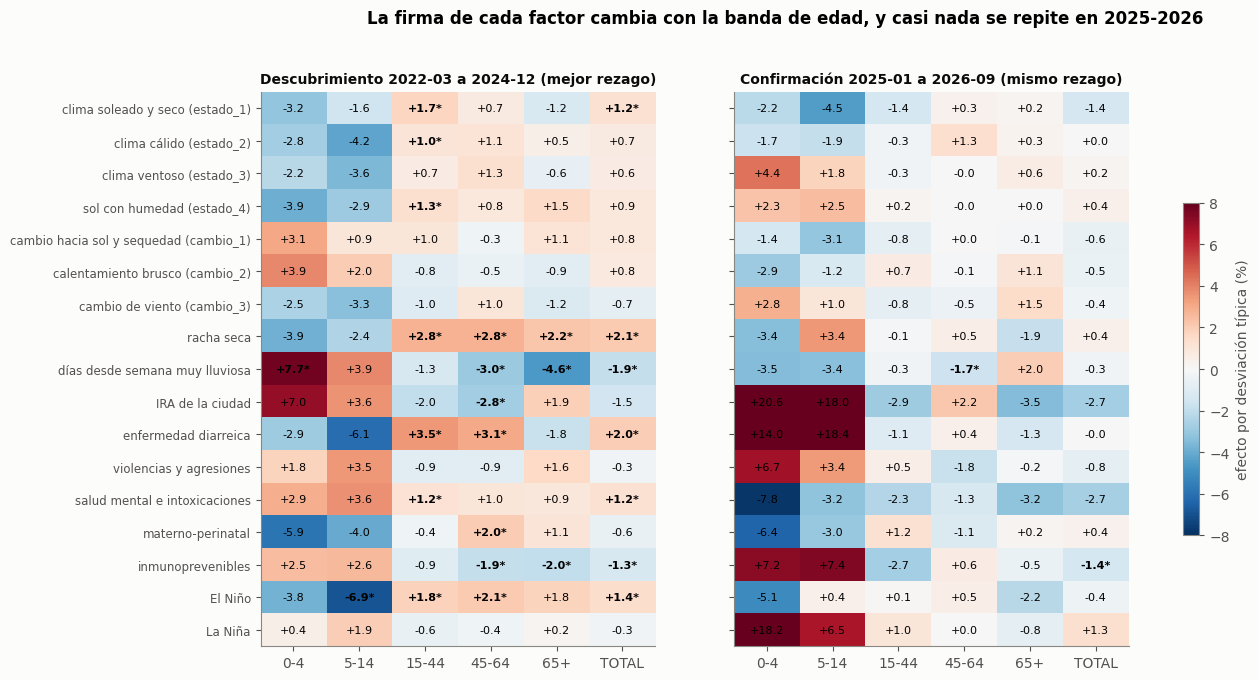

Rezago elegido en el descubrimiento (semanas):


,edad 0-4,edad 5-14,edad 15-44,edad 45-64,edad 65+,TOTAL
clima soleado y seco (estado_1),4,2,0,2,2,0
clima cálido (estado_2),2,4,4,3,3,0
clima ventoso (estado_3),4,1,3,3,0,3
sol con humedad (estado_4),4,1,0,2,4,0
cambio hacia sol y sequedad (cambio_1),0,3,0,4,0,0
calentamiento brusco (cambio_2),0,0,2,4,4,0
cambio de viento (cambio_3),4,1,4,3,0,4
racha seca,2,3,3,3,0,3
días desde semana muy lluviosa,0,2,4,4,2,3
IRA de la ciudad,0,0,2,2,1,2


In [8]:
BASE = lambda v: v.split(" (")[0]
LAGDE = lambda v: int(re.search(r"−(\d)", v).group(1)) if "sem)" in v else 0
orden = (list(IC.columns) + list(FAM.columns) + ["el_nino", "la_nina"])
partes = ["edad 0-4", "edad 5-14", "edad 15-44", "edad 45-64", "edad 65+", "TOTAL"]
D1 = pd.DataFrame(index=orden, columns=partes, dtype=float); Q1 = D1.copy(); D2 = D1.copy(); P2 = D1.copy(); LAG = D1.copy()
for c in partes:
    T = RB[c].assign(b=lambda d: d.variable.map(BASE)); Tc = RC[c].set_index("variable")
    for b, g in T.groupby("b"):
        r = g.sort_values("p").iloc[0]; D1.loc[b, c] = r["efecto %"]; Q1.loc[b, c] = r.q
        LAG.loc[b, c] = LAGDE(r.variable)
        if r.variable in Tc.index: D2.loc[b, c] = Tc.loc[r.variable, "efecto %"]; P2.loc[b, c] = Tc.loc[r.variable, "p"]
fig, ax = plt.subplots(1, 2, figsize=(14, 7.2), sharey=True)
for a, M, tit in [(ax[0], D1, "Descubrimiento 2022-03 a 2024-12 (mejor rezago)"), (ax[1], D2, "Confirmación 2025-01 a 2026-09 (mismo rezago)")]:
    im = a.imshow(M.values, cmap="RdBu_r", vmin=-8, vmax=8, aspect="auto"); a.grid(False)
    a.set_xticks(range(len(partes)), [p.replace("edad ", "") for p in partes]); a.set_title(tit, fontsize=10)
    for (i, j), v in np.ndenumerate(M.values):
        if np.isnan(v): continue
        sig = (Q1.values[i, j] < .10) if M is D1 else (Q1.values[i, j] < .10 and P2.values[i, j] < .05 and np.sign(v) == np.sign(D1.values[i, j]))
        a.text(j, i, f"{v:+.1f}" + ("*" if sig else ""), ha="center", va="center", fontsize=8, fontweight="bold" if sig else "normal")
ETQ = {"estado_1": "clima soleado y seco (estado_1)", "estado_2": "clima cálido (estado_2)", "estado_3": "clima ventoso (estado_3)",
       "estado_4": "sol con humedad (estado_4)", "cambio_1": "cambio hacia sol y sequedad (cambio_1)", "cambio_2": "calentamiento brusco (cambio_2)",
       "cambio_3": "cambio de viento (cambio_3)", "racha_seca": "racha seca", "dias_desde_semana_muy_lluviosa": "días desde semana muy lluviosa",
       "respiratoria": "IRA de la ciudad", "digestiva": "enfermedad diarreica", "violencias_y_agresiones": "violencias y agresiones",
       "salud_mental_e_intoxicaciones": "salud mental e intoxicaciones", "materno_perinatal": "materno-perinatal",
       "inmunoprevenibles": "inmunoprevenibles", "el_nino": "El Niño", "la_nina": "La Niña"}
ax[0].set_yticks(range(len(orden)), [ETQ[o] for o in orden], fontsize=8.5)
fig.colorbar(im, ax=ax, shrink=.6, label="efecto por desviación típica (%)")
fig.suptitle("La firma de cada factor cambia con la banda de edad, y casi nada se repite en 2025-2026", fontweight="bold", y=.995)
plt.show()
print("Rezago elegido en el descubrimiento (semanas):"); display(LAG.astype(int).rename(index=ETQ))

**Lectura.** El mapa muestra dos cosas: que las bandas responden con signos distintos al mismo factor, y que ese patrón no se mantiene en el periodo de confirmación.

En el descubrimiento (panel izquierdo) la racha seca sube las tres bandas adultas (+2,2 a +2,8 %) y el total (+2,1 %) y tiene signo contrario, sin significancia, en las pediátricas (−3,9 y −2,4 %). Los días desde la semana muy lluviosa invierten el signo con la edad: +7,7 % en 0-4, +3,9 % en 5-14, −3,0 % en 45-64 y −4,6 % en 65+. La enfermedad diarreica de la ciudad se asocia con más triages en 15-44 y 45-64 (+3,5 y +3,1 %), y la IRA, con menos en 45-64 (−2,8 %). Esto es la firma por edad que se buscaba.

En la confirmación (panel derecho) solo llevan asterisco las celdas preseleccionadas en el descubrimiento que repiten signo con p < 0,05: la lluvia reciente en 45-64 y las enfermedades inmunoprevenibles en el total. El resto del panel es más ruido que patrón, con un par de excepciones llamativas en las bandas pediátricas (IRA +20,6 y +18,0 %, diarrea +14,0 y +18,4 %, La Niña +18,2 % en 0-4) que se miden sobre 52 semanas de 2025 y no estaban preseleccionadas; no se leen como confirmaciones. La escala se satura en ±8 %. Un efecto que reaparece con signo contrario, como la lluvia reciente en los mayores, no solo se desvanece: sugiere que lo medido en 2022-2024 dependía de condiciones de esos años.

## Las familias de enfermedad en las bandas pediátricas, sin selección de rezago

La hipótesis respiratoria apunta a los niños. Para no depender de un rezago elegido, se muestran los tres rezagos
(0, 1 y 2 semanas) de la IRA y de la enfermedad diarreica de la ciudad en las dos bandas pediátricas, en cada periodo.

In [9]:
filas = []
for c in ["edad 0-4", "edad 5-14"]:
    for fam in ["respiratoria", "digestiva"]:
        for L in range(3):
            v = f"{fam} (−{L} sem)"
            a = RB[c].set_index("variable").loc[v]; b = RC[c].set_index("variable").loc[v]
            filas.append({"banda": c, "familia": ETQ[fam], "rezago": L, "efecto 2022-24 %": a["efecto %"], "p": a.p,
                          "efecto 2025 %": b["efecto %"], "p 2025": b.p, "semanas 2025": int(b.n)})
display(pd.DataFrame(filas).round(3).set_index(["banda", "familia", "rezago"]))

efecto 2022-24 %      p  efecto 2025 %  \
banda     familia              rezago                                           
edad 0-4  IRA de la ciudad     0                  7.009  0.004         20.613   
                               1                  5.326  0.089          7.083   
                               2                 -0.318  0.923        -23.096   
          enfermedad diarreica 0                 -0.543  0.853         11.361   
                               1                 -0.457  0.894         16.548   
                               2                 -2.865  0.326         14.047   
edad 5-14 IRA de la ciudad     0                  3.608  0.231         18.027   
                               1                 -0.241  0.930          2.604   
                               2                 -0.561  0.878        -22.957   
          enfermedad diarreica 0                 -3.808  0.173         12.902   
                               1                 -4.437  0.099         17.288   
                               2                 -6.092  0.018         18.380   

                                       p 2025  semanas 2025  
banda     familia              rezago                        
edad 0-4  IRA de la ciudad     0        0.035            52  
                               1        0.537            52  
                               2        0.001            52  
          enfermedad diarreica 0        0.249            51  
                               1        0.034            52  
                               2        0.036            52  
edad 5-14 IRA de la ciudad     0        0.046            52  
                               1        0.782            52  
                               2        0.001            52  
          enfermedad diarreica 0        0.230            51  
                               1        0.024            52  
                               2        0.002            52

**Lectura.** De las 12 combinaciones de familia, banda y rezago, solo una conserva signo y significancia nominal en los dos periodos: la IRA de la ciudad en la misma semana para los menores de 5 años.

Ahí el efecto es +7,0 % (p = 0,004) en 2022-2024 y +20,6 % (p = 0,035) en 2025. En 5-14 el signo se conserva (+3,6 y +18,0 %), pero en 2022-2024 no es significativo (p = 0,23). Es el mecanismo del proyecto, más consultas respiratorias en la ciudad y más triages pediátricos, y va en el sentido esperado. Las otras combinaciones lo contradicen: a dos semanas la IRA de 0-4 pasa de −0,3 % a −23,1 % (p = 0,001), y la diarrea de 5-14 pasa de −4,4 y −6,1 % a +17,3 y +18,4 %. Con 52 semanas en 2025, tres rezagos muy correlacionados y 12 filas sin corrección por pruebas múltiples, el resultado se trata como hipótesis para ensayar con más datos, no como hallazgo. Un límite adicional es que la relación en la misma semana podría ser parcialmente contable, si las consultas del hospital forman parte de lo que notifica la vigilancia de la ciudad. Este análisis no puede descartarlo.

## Estabilidad año por año de las señales preseleccionadas

El mismo rezago elegido en el descubrimiento se mide en cada año por separado (sin mes fijo, con 40-52 semanas por
año; 2026 llega hasta septiembre). Una señal real debería conservar el signo.

In [10]:
sel = [("edad 65+", "dias_desde_semana_muy_lluviosa"), ("edad 45-64", "dias_desde_semana_muy_lluviosa"), ("edad 15-44", "racha_seca"),
       ("edad 45-64", "racha_seca"), ("edad 65+", "racha_seca"), ("edad 15-44", "digestiva"), ("TOTAL", "racha_seca")]
filas = []
for c, b in sel:
    T = RB[c].assign(b=lambda d: d.variable.map(BASE)); v = T[T.b.eq(b)].sort_values("p").iloc[0].variable
    xs = (X[v] - X[v].loc[:"2024"].mean()) / X[v].loc[:"2024"].std()
    fila = {"parte": c, "variable": v}
    for a in range(2022, 2027):
        D = pd.concat([RESID_F[c].rename("y"), xs.rename("x")], axis=1).loc[str(a)].dropna()
        if len(D) < 25 or D.x.std() == 0: fila[str(a)] = np.nan; continue
        r = sm.OLS(D.y, sm.add_constant(D[["x"]])).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
        fila[str(a)] = round(100 * (np.exp(r.params["x"]) - 1), 1)
    filas.append(fila)
pd.DataFrame(filas).set_index(["parte", "variable"])

,,2022,2023,2024,2025,2026
parte,variable,,,,,
edad 65+,dias_desde_semana_muy_lluviosa (−2 sem),1.3,-1.3,-6.3,3.9,2.8
edad 45-64,dias_desde_semana_muy_lluviosa (−4 sem),-2.2,8.1,-6.8,0.5,0.3
edad 15-44,racha_seca (−3 sem),-0.3,2.6,2.0,-2.7,-0.4
edad 45-64,racha_seca (−3 sem),2.9,0.7,1.8,-3.2,0.4
edad 65+,racha_seca (−0 sem),-4.1,3.8,1.1,0.9,-2.3
edad 15-44,digestiva (−0 sem),1.5,4.5,5.7,0.3,NaN
TOTAL,racha_seca (−3 sem),2.9,1.6,1.0,-2.7,0.5


**Lectura.** Al medir las señales año por año aparece que lo descubierto vivía en años concretos.

La lluvia reciente en 65+ (rezago de 2 semanas) tiene el signo esperado, negativo, solo en 2023 (−1,3 %) y sobre todo en 2024 (−6,3 %), y es positiva en 2022 (+1,3 %), 2025 (+3,9 %) y 2026 (+2,8 %). Es decir, el efecto del descubrimiento (−4,6 %) es sobre todo de 2024, el año de mayor volumen de la serie, y no se repite. La racha seca en 15-44 y 45-64 es positiva en 2023 y 2024 y negativa en 2025 (−2,7 y −3,2 %). La lluvia reciente en 45-64, la única confirmación de la tabla anterior, es +0,5 % en 2025 y +0,3 % en 2026 al medirla año por año sin mes fijo, de modo que la confirmación agrupada es frágil. La enfermedad diarreica en 15-44 es la única con el mismo signo en los cuatro años con dato (+1,5, +4,5, +5,7 y +0,3 %), aunque decae hasta casi cero; la fuente solo cubre hasta 2025.

Cada uno de estos resultados está sujeto a que cada año tiene entre 40 y 52 semanas. Aun así, ninguna de las señales del clima resulta una propiedad estable de la banda de edad.

# 4. Episodios locales: Feria, deslizamientos y terremoto

Un promedio semanal diluye lo que dura días. Para los episodios con fecha se compara cada banda en la ventana del
episodio con ventanas vecinas del mismo largo (múltiplos de 7 días, para equilibrar los días de la semana). Se
mide la **participación de la banda en el triage del día** (el denominador es el total), que descuenta cualquier
cambio general de volumen, y el cambio del conteo medio.

Los episodios son pocos (6 Ferias, 3 deslizamientos con fecha precisa, 1 terremoto), de modo que se muestran uno
por uno, no como promedio con significancia.

Cambio del conteo medio diario, días de Feria frente a los 14 días siguientes (%):


Feria,2020,2022,2023,2024,2025,2026
banda,,,,,,
0-4,-9.5,51.9,-4.5,-46.0,-4.9,-24.8
5-14,9.6,41.6,-15.0,-15.3,-2.4,-0.5
15-44,5.1,9.6,-7.0,-14.2,-0.3,-1.2
45-64,-16.5,-2.0,-11.4,-13.4,-2.9,4.9
65+,1.1,-4.2,-14.6,-12.3,0.1,0.9
TOTAL,-0.9,6.5,-9.7,-14.3,-1.1,-0.6


Cambio de la participación de la banda entre los triages con edad (puntos porcentuales):


Feria,2020,2022,2023,2024,2025,2026
banda,,,,,,
0-4,-0.25,0.61,0.11,-0.65,-0.10,-1.02
5-14,0.49,0.86,-0.22,-0.03,-0.07,0.00
15-44,2.84,1.75,1.62,0.04,0.31,-0.32
45-64,-3.56,-1.46,-0.38,0.21,-0.37,1.00
65+,0.48,-1.76,-1.13,0.44,0.24,0.33


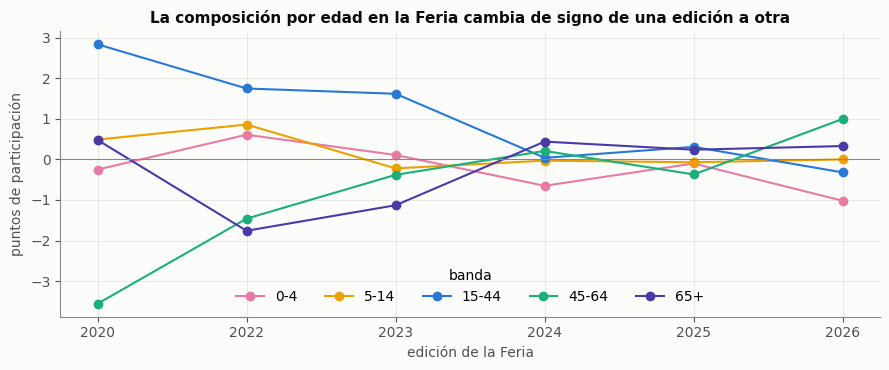

In [11]:
ev = pd.read_csv(RAIZ / "calendarios/eventos_manizales_2020_2026.csv")
fer = ev[ev.nombre_evento.eq("Feria de Manizales") & ev.estado.eq("realizado")][["anio", "fecha_inicio", "fecha_fin"]]
B = P[[f"edad {b}" for b in BANDAS]].copy(); B.columns = BANDAS; B["TOTAL"] = P.TOTAL
def ventana(ini, fin):
    w = B.loc[ini:fin]; return w.mean(), (w[BANDAS].sum() / w[BANDAS].sum().sum() * 100)
filas = []
for _, r in fer.iterrows():
    a, b = pd.Timestamp(r.fecha_inicio), pd.Timestamp(r.fecha_fin)
    m_f, s_f = ventana(a, b); m_p, s_p = ventana(b + pd.Timedelta(days=1), b + pd.Timedelta(days=14))
    for bd in BANDAS + ["TOTAL"]:
        filas.append({"Feria": int(r.anio), "banda": bd, "conteo": 100 * (m_f[bd] / m_p[bd] - 1),
                      "participación": (s_f[bd] - s_p[bd]) if bd != "TOTAL" else np.nan})
F = pd.DataFrame(filas)
M1 = F.pivot(index="banda", columns="Feria", values="conteo").reindex(BANDAS + ["TOTAL"]).round(1)
M2 = F.pivot(index="banda", columns="Feria", values="participación").reindex(BANDAS).round(2)
print("Cambio del conteo medio diario, días de Feria frente a los 14 días siguientes (%):"); display(M1)
print("Cambio de la participación de la banda entre los triages con edad (puntos porcentuales):"); display(M2)
fig, ax = plt.subplots(figsize=(9, 3.8))
for bd, col in zip(BANDAS, COLB):
    ax.plot(M2.columns.astype(str), M2.loc[bd], marker="o", color=col, label=bd)
ax.axhline(0, color=MUDO, lw=.8); ax.set_ylabel("puntos de participación"); ax.set_xlabel("edición de la Feria")
ax.set_title("La composición por edad en la Feria cambia de signo de una edición a otra"); ax.legend(title="banda", ncol=5, loc="lower center")
plt.tight_layout(); plt.show()

**Lectura.** La Feria no deja una huella reproducible en la composición por edad.

La participación de 15-44 sube 2,84, 1,75 y 1,62 puntos en las Ferias de 2020, 2022 y 2023, y casi nada en 2024, 2025 y 2026 (+0,04, +0,31 y −0,32). La de 45-64 hace lo contrario (−3,56, −1,46 y −0,38 puntos, luego +0,21, −0,37 y +1,00). En las bandas pediátricas los cambios van de +51,9 % en 2022 a −46,0 % en 2024 en 0-4, y de +41,6 % a −15,3 % en 5-14, rangos que reflejan los 5 a 10 triages diarios que tiene cada una. El total de la Feria frente a los 14 días siguientes no tiene dirección fija (−0,9, +6,5, −9,7, −14,3, −1,1 y −0,6 %).

Dos límites. La Feria se midió antes por aseguradora, donde empuja a SOAT (+36,9 ± 5,5 %) y a los particulares, que son pacientes de todas las edades, y la edad no separa ese efecto. Además los 14 días siguientes contienen el regreso de vacaciones, que también mueve la composición. Con seis ediciones no se puede decir si la Feria cambia la edad de quien consulta, y los datos tampoco la descartan.

In [12]:
casos = [("Deslizamientos múltiples", "2022-10-20", 14, 14, 0), ("Deslizamientos múltiples", "2025-04-08", 14, 14, 0),
         ("Deslizamientos múltiples", "2026-04-18", 14, 14, 0), ("Terremoto M7,4, días 0-13", "2026-08-10", 28, 14, 0),
         ("Terremoto M7,4, días 14-27", "2026-08-10", 28, 14, 14)]
filas = []
for nombre, f, pre, post, off in casos:
    f = pd.Timestamp(f)
    m_pre, s_pre = ventana(f - pd.Timedelta(days=pre), f - pd.Timedelta(days=1))
    m_po, s_po = ventana(f + pd.Timedelta(days=off), f + pd.Timedelta(days=off + post - 1))
    filas.append({"episodio": f"{nombre} ({f.date()})", **{bd: round(100 * (m_po[bd] / m_pre[bd] - 1), 1) for bd in BANDAS + ["TOTAL"]}})
    filas.append({"episodio": "   participación (puntos)", **{bd: round(s_po[bd] - s_pre[bd], 2) for bd in BANDAS}})
# control: las mismas ventanas del calendario en 2022-2025 (sin terremoto)
ctrl = {"0-13": [], "14-27": []}
for a in range(2022, 2026):
    f = pd.Timestamp(f"{a}-08-10")
    m_pre, s_pre = ventana(f - pd.Timedelta(days=28), f - pd.Timedelta(days=1))
    for k, off in [("0-13", 0), ("14-27", 14)]:
        m_po, _ = ventana(f + pd.Timedelta(days=off), f + pd.Timedelta(days=off + 13))
        ctrl[k].append(100 * (m_po / m_pre - 1))
for k in ctrl:
    C_ = pd.concat(ctrl[k], axis=1)
    filas.append({"episodio": f"Control: mismas fechas 2022-2025, días {k} (promedio)", **{bd: round(C_.loc[bd].mean(), 1) for bd in BANDAS + ["TOTAL"]}})
    filas.append({"episodio": "   mínimo a máximo de los 4 años", **{bd: f"{C_.loc[bd].min():.0f} a {C_.loc[bd].max():.0f}" for bd in BANDAS + ["TOTAL"]}})
EP = pd.DataFrame(filas).set_index("episodio")
print("Cambio del conteo medio diario frente a la ventana previa (%):"); EP

Cambio del conteo medio diario frente a la ventana previa (%):


,0-4,5-14,15-44,45-64,65+,TOTAL
episodio,,,,,,
Deslizamientos múltiples (2022-10-20),-4.3,-14.6,2.2,-0.8,-3.2,-0.4
participación (puntos),-0.11,-0.75,1.45,-0.08,-0.51,NaN
Deslizamientos múltiples (2025-04-08),-1.5,-19.6,-10.9,-0.4,-5.3,-8.2
participación (puntos),0.33,-0.94,-1.51,1.52,0.6,NaN
Deslizamientos múltiples (2026-04-18),31.1,17.1,-7.0,-13.9,-13.5,-7.6
participación (puntos),1.16,1.17,0.37,-1.25,-1.44,NaN
"Terremoto M7,4, días 0-13 (2026-08-10)",-32.6,-20.9,-15.6,-18.2,-6.1,-15.1
participación (puntos),-0.86,-0.35,-0.29,-0.66,2.16,NaN
"Terremoto M7,4, días 14-27 (2026-08-10)",-31.6,-14.9,9.7,-0.7,9.8,4.8


**Lectura.** Los deslizamientos no dejan un patrón por edad; el terremoto de agosto de 2026 sí deja una caída en todas las bandas, y las bandas se recuperan de forma distinta.

Deslizamientos: en los tres episodios con fecha precisa el total cambia −0,4, −8,2 y −7,6 %, y las bandas se mueven en direcciones distintas cada vez. El único movimiento llamativo es del 18 de abril de 2026 (0-4 +31,1 %, 5-14 +17,1 %, mayores de 45 −13,5 a −13,9 %); en los otros dos casos no se repite. Estos episodios caen en la temporada de lluvias y de enfermedad respiratoria, así que no se pueden separar de ella.

Terremoto, días 0 a 13: todas las bandas caen respecto de las cuatro semanas previas, y por debajo de lo que ocurrió en las mismas fechas de 2022-2025: 0-4, −32,6 % contra −12,5 % en los años de control; 5-14, −20,9 contra −7,4; 15-44, −15,6 contra −1,0; 45-64, −18,2 contra −6,7; 65+, −6,1 contra +5,1; total, −15,1 contra −1,9. La diferencia con el control es de entre 11 y 20 puntos. Días 14 a 27: las bandas de 15-44 y 65+ se recuperan por encima del control (+9,7 y +9,8 % contra +0,5 y +1,5), y 0-4 sigue en −31,6 % (control −11,4 %). Es decir, los adultos y los mayores recuperan; mientras que los menores de 5 años no han vuelto a su nivel a las seis semanas.

La cautela está en los números pequeños: 0-4 tiene alrededor de 100 triages por ventana de 14 días, una oscilación de unos 10 puntos solo por azar. Aun así, sus valores quedan fuera del rango de los cuatro años de control (−21 a +4 % y −22 a +11 %). Un único episodio no permite decir si la menor recuperación pediátrica es una propiedad del terremoto o de la banda.

# 5. La red de aseguradoras y las bandas

La caída del volumen desde 2024 se explicó por Nueva EPS (cuadernos 07 y 18). Si es así, las bandas deberían
caer según cuánto de su demanda pasa por esa aseguradora. No existe el cruce de edad por aseguradora, así que se
estima de forma indirecta: la **elasticidad** de cada banda frente al cambio en 28 días de los triages de Nueva
EPS y del resto. Ambas variables son conteos que incluyen a los pacientes de la banda, por lo que la relación
es en parte contable; lo que se compara es su tamaño entre bandas, no su causalidad.

Observaciones semanales: 234


,elasticidad a Nueva EPS,IC95 inf,IC95 sup,elasticidad al resto,R2
banda,,,,,
0-4,0.52,0.26,0.78,1.51,0.35
5-14,0.56,0.37,0.74,1.33,0.44
15-44,0.40,0.30,0.50,0.48,0.83
45-64,0.47,0.40,0.55,0.45,0.73
65+,0.56,0.50,0.63,0.20,0.63
TOTAL,0.47,0.41,0.52,0.49,0.97


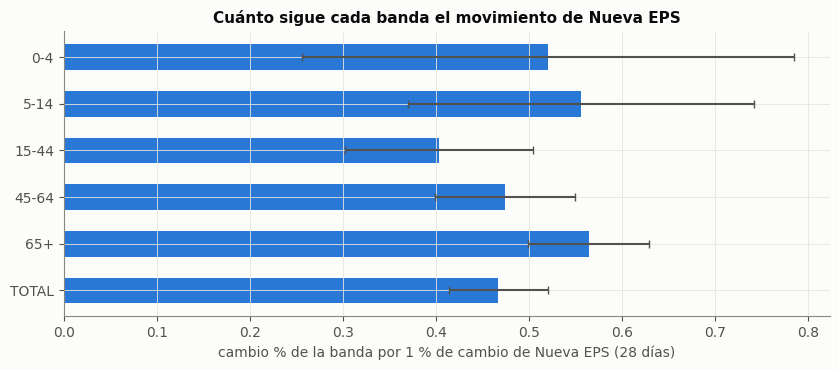

In [13]:
red = ix.red_diaria()
R28 = lambda s: np.log1p(s.rolling(28, min_periods=20).sum()) - np.log1p(s.rolling(28, min_periods=20).sum().shift(28))
V = pd.DataFrame({b: R28(P[f"edad {b}"]) for b in BANDAS})
V["TOTAL"] = R28(P.TOTAL)
Z = V.join(red[["cambio_nueva_eps_28d", "cambio_resto_28d"]]).loc["2022-04-01":"2026-09-20"].iloc[::7].dropna()
filas = []
for b in BANDAS + ["TOTAL"]:
    r = sm.OLS(Z[b], sm.add_constant(Z[["cambio_nueva_eps_28d", "cambio_resto_28d"]])).fit(cov_type="HAC", cov_kwds={"maxlags": 8})
    ci = r.conf_int()
    filas.append({"banda": b, "elasticidad a Nueva EPS": r.params["cambio_nueva_eps_28d"],
                  "IC95 inf": ci.loc["cambio_nueva_eps_28d", 0], "IC95 sup": ci.loc["cambio_nueva_eps_28d", 1],
                  "elasticidad al resto": r.params["cambio_resto_28d"], "R2": r.rsquared})
EL = pd.DataFrame(filas).set_index("banda")
print("Observaciones semanales:", len(Z)); display(EL.round(2))
fig, ax = plt.subplots(figsize=(8.5, 3.8))
y = np.arange(len(EL)); ax.barh(y, EL["elasticidad a Nueva EPS"], color=AZUL, height=.55)
ax.errorbar(EL["elasticidad a Nueva EPS"], y, xerr=[EL["elasticidad a Nueva EPS"] - EL["IC95 inf"], EL["IC95 sup"] - EL["elasticidad a Nueva EPS"]], fmt="none", ecolor=TINTA2, capsize=3)
ax.set_yticks(y, EL.index); ax.invert_yaxis(); ax.set_xlabel("cambio % de la banda por 1 % de cambio de Nueva EPS (28 días)")
ax.set_title("Cuánto sigue cada banda el movimiento de Nueva EPS"); plt.tight_layout(); plt.show()

**Lectura.** Las bandas siguen a Nueva EPS con elasticidades parecidas, entre 0,40 y 0,56, y se diferencian más en cuánto siguen al resto de aseguradoras.

Por cada 1 % de cambio de los triages de Nueva EPS en 28 días, el total cambia 0,47 % (IC 95 %: 0,41 a 0,52). Las bandas de 65+ y 5-14 siguen más (0,56), 45-64 está en 0,47 y 15-44 en 0,40 (IC 95 %: 0,30 a 0,50). La diferencia está en el resto: los mayores de 65 casi no siguen a las otras aseguradoras (0,20, frente a 0,48 y 0,45 de 15-44 y 45-64), de modo que su volumen depende más de una sola aseguradora. Las bandas pediátricas tienen elasticidades al resto de 1,51 y 1,33 con R² de 0,35 y 0,44, producto del ruido de contar pocos pacientes por semana.

Estas elasticidades son relaciones contables, porque Nueva EPS y el resto incluyen a los pacientes de la propia banda, y se estiman con 234 observaciones semanales solapadas. Describen con qué fuerza se mueve cada banda con cada pagador, no por qué. No explican, por ejemplo, que 15-44 haya caído más que 65+ desde 2024; explicarlo requiere el cruce de edad por aseguradora, que no existe en los datos.

# 6. El pronóstico por banda

El modelo de contexto holístico (24 variables de clima, enfermedad, red y regímenes) se entrenó para cada banda y
se evaluó en 2025 con origen rodante, de 1 a 7 días. Se leen los resultados guardados. La banda de 5 a 14 años se
excluye: su corrida guardada es anterior a la corrección del logaritmo con ceros (log(y + 1)) y conserva valores
infinitos, así que no es utilizable.

In [14]:
filas = []
for k, nom in [("04", "0-4"), ("1544", "15-44"), ("4564", "45-64"), ("65", "65+")]:
    d = pd.read_parquet(RAIZ / f"salidas/pronostico/hb{k}_2025/lightgbm.parquet")
    assert not np.isinf(d.select_dtypes("number")).any().any()
    real = d.drop_duplicates("fecha").set_index("fecha").real
    d = d.assign(ingenuo=d.fecha.map(lambda f: real.get(f - pd.Timedelta(days=7), np.nan)))
    d = d[(d.real > 0) & d.ingenuo.notna()]
    for h in (1, 7):
        g = d[d.h.eq(h)]
        filas.append({"banda": nom, "h (días)": h, "MAPE modelo %": 100 * ((g.q50 - g.real).abs() / g.real).mean(),
                      "MAPE «igual día semana pasada» %": 100 * ((g.ingenuo - g.real).abs() / g.real).mean(),
                      "cobertura del 80 % (q10-q90) %": 100 * ((g.real >= g.q10) & (g.real <= g.q90)).mean(), "días": len(g)})
PB = pd.DataFrame(filas).set_index(["banda", "h (días)"]).round(1)
PB

MAPE modelo %  MAPE «igual día semana pasada» %  \
banda h (días)                                                    
0-4   1                  43.1                              56.1   
      7                  43.9                              56.4   
15-44 1                  11.5                              15.9   
      7                  12.3                              16.0   
45-64 1                  16.1                              22.8   
      7                  16.4                              22.8   
65+   1                  16.7                              22.0   
      7                  17.6                              22.0   

                cobertura del 80 % (q10-q90) %  días  
banda h (días)                                        
0-4   1                                   67.2   357  
      7                                   69.1   363  
15-44 1                                   72.9   358  
      7                                   70.1   364  
45-64 1                                   72.3   358  
      7                                   72.5   364  
65+   1                                   61.5   358  
      7                                   60.7   364

**Lectura.** Los modelos por banda con contexto mejoran el error frente a repetir el día de la semana pasada, pero lo que no se puede concluir es que lo haga el contexto.

A un día, el MAPE es de 11,5 % en 15-44 (contra 15,9 % del día igual de la semana pasada), 16,1 % en 45-64 (22,8 %), 16,7 % en 65+ (22,0 %) y 43,1 % en 0-4 (56,1 %). A siete días es prácticamente el mismo. La cobertura del intervalo del 80 % es insuficiente en todas: entre 61 y 73 %, de modo que los intervalos son demasiado estrechos. En 0-4 el MAPE se calcula sin los días con cero triages.

El comparador es débil, y no existe una corrida por banda con solo calendario, así que no hay un control que diga cuánto de la mejora viene del contexto. Para el total, el mismo contexto no mejoró la predicción en 2025 (cuaderno 23). La banda de 5-14 no tiene resultado utilizable. Estas cifras deben leerse como el desempeño de un modelo por banda, no como evidencia de que el contexto externo actúe en cada una.

# 7. Conclusiones y límites

**Conclusiones.**

1. **El triage se puede repartir completo desde 2020** por edad (cinco bandas) o por condición obstétrica. Los diagnósticos no sirven como partición porque cubren el 41 %.
2. **Las partes tienen otra forma que el total.** La estación pediátrica tiene una amplitud de 86,8 y 63,6 puntos, contra 21,6 del total, y desde 2024 el volumen cayó un 27,8 % en 15-44 y un 27,3 % en 45-64, pero no cayó en 0-4 (+1,5 %). Con el total, estas diferencias se promedian.
3. **En el descubrimiento (2022-2024) el contexto aparece más fuerte en las partes**: efectos máximos de 3,1 a 7,7 %, contra 2,1 % en el total, y 32 pruebas que sobreviven en las bandas contra 11 en el total. Cada banda tuvo su propia firma: la lluvia reciente en los mayores, la racha seca y la diarrea de la ciudad en los adultos, el tiempo transcurrido desde la última lluvia fuerte en los menores de 5 años.
4. **En 2025-2026 casi nada se repite.** De 32 pruebas, 8 conservan el signo, 1 se confirma y 4 se invierten con p < 0,05. La lluvia reciente en los mayores es sobre todo un fenómeno de 2024. La excepción con mecanismo es la IRA de la ciudad en la misma semana en 0-4 años (+7,0 % y +20,6 %), que se queda como hipótesis.
5. **Los episodios se ven mejor en las partes.** El terremoto de agosto de 2026 baja el triage 11 a 20 puntos por debajo del control en todas las bandas, y a las seis semanas los adultos y los mayores se recuperan y los menores de 5 años no.
6. **El modelo por bandas del cuaderno 22** se justifica por la forma distinta de cada banda y por el estado de la red de aseguradoras, no por una firma climática estable.

**Límites del análisis.**

- Las bandas pediátricas tienen 15 a 25 triages por semana y un ruido de 23 a 26 %; no pueden mostrar efectos de 2-3 %, y los de 7 % se confunden con el ruido.
- La confirmación tiene 89 semanas, y la de las familias de enfermedad solo 52, porque los microdatos llegan hasta diciembre de 2025.
- El Niño, La Niña y los episodios son pocos eventos largos y no se pueden separar de la fecha.
- La relación con las enfermedades de la ciudad podría ser en parte contable, si las consultas del hospital forman parte de lo que notifica la vigilancia.
- No existe el cruce de edad por aseguradora ni por condición obstétrica, que son la partición que mejor distinguiría el efecto de la red del efecto de la población.
- La partición por motivo de consulta no entra porque el corpus de texto no está procesado por completo.